4. Registration with Segmented Data- Dipy:

• Perform Affine and Non-linear registration of the segmented subject volume to the segmented atlas volume using Dipy.
 
• Save the registered volumes in NIfTI format as segmented_deformed_patient.nii, segmented_affine_patient.nii

• Compare the registration in 2D using different plots. Create a figure with one slice (axial, sagittal, or coronal) of the original volume of 
the atlas, and how they overlap. Create a second figure with the same slice, but compare the registered volume and the atlas and how they overlap. 

In [1]:
# Set up our usual routines and configuration
import os
import numpy as np
np.set_printoptions(precision=4, suppress=True)
import matplotlib.pyplot as plt
# - set gray colormap and nearest neighbor interpolation by default
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'
import nibabel as nib
from dipy.viz import regtools
from dipy.align.imaffine import (AffineMap,
                                  MutualInformationMetric,
                                  AffineRegistration)
from dipy.align.transforms import (TranslationTransform3D,
                                    RigidTransform3D,
                                    AffineTransform3D)
from dipy.align.imwarp import SymmetricDiffeomorphicRegistration
from dipy.align.metrics import CCMetric  # Import CCMetric here

C:\Users\carla\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\dipy\viz\__init__.py:22: UserWarning: You do not have FURY installed. Therefore, 3D visualization functions will not work for you. Please install or upgrade FURY using pip install -U furyFor detailed installation instructions visit: https://fury.gl/
  warnings.warn(
C:\Users\carla\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


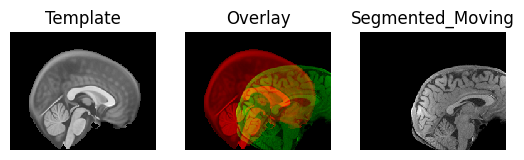

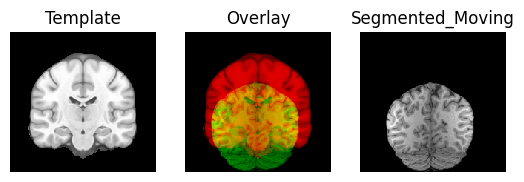

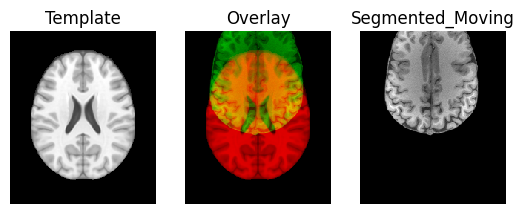

Optimizing level 2 [max iter: 10]
Optimizing level 1 [max iter: 10]
Optimizing level 0 [max iter: 5]


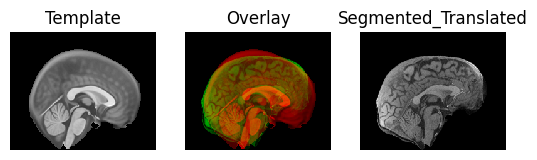

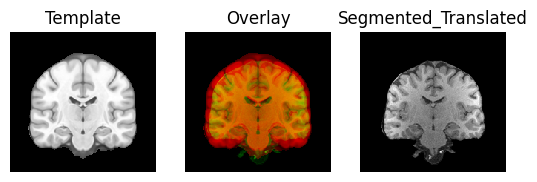

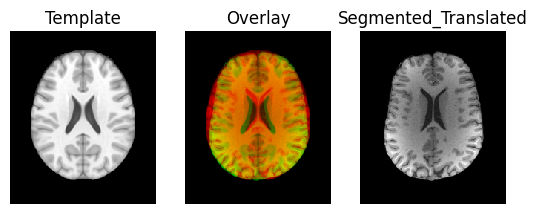

Optimizing level 2 [max iter: 10]
Optimizing level 1 [max iter: 10]
Optimizing level 0 [max iter: 5]


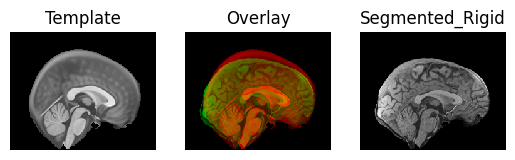

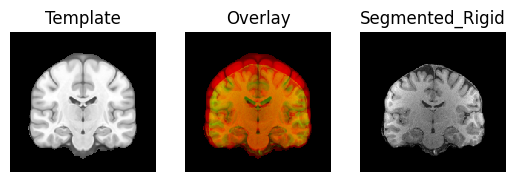

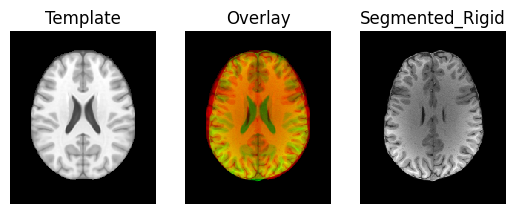

Optimizing level 2 [max iter: 1000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]


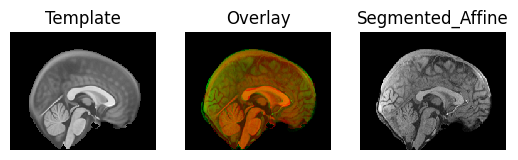

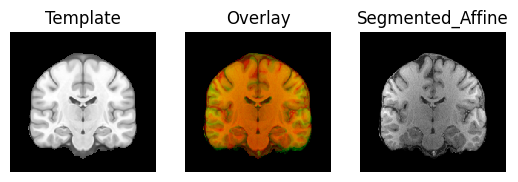

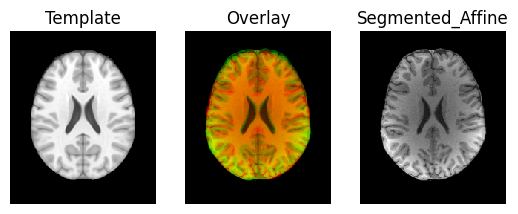

In [2]:
# File paths
moving_path = "segmented_patient.nii.gz"
template_path = "atlas_segmented.nii"

# Load images
moving_img = nib.load(moving_path)
template_img = nib.load(template_path)

# Extract data and affine matrices
moving_data = moving_img.get_fdata()
moving_affine = moving_img.affine
template_data = template_img.get_fdata()
template_affine = template_img.affine

# Initial resampling for visualization
identity = np.eye(4)
affine_map = AffineMap(identity,
                       template_data.shape, template_affine,
                       moving_data.shape, moving_affine)
resampled = affine_map.transform(moving_data)

# Overlay slices for initial visualization
regtools.overlay_slices(template_data, resampled, None, 0, "Template", "Segmented_Moving")
plt.show()
regtools.overlay_slices(template_data, resampled, None, 1, "Template", "Segmented_Moving")
plt.show()
regtools.overlay_slices(template_data, resampled, None, 2, "Template", "Segmented_Moving")
plt.show()

# Affine registration setup
nbins = 32
sampling_prop = None
metric = MutualInformationMetric(nbins, sampling_prop)
level_iters = [10, 10, 5]
sigmas = [3.0, 1.0, 0.0]
factors = [4, 2, 1]

affreg = AffineRegistration(metric=metric, level_iters=level_iters,
                            sigmas=sigmas, factors=factors)

# Translation optimization
transform = TranslationTransform3D()
params0 = None
translation = affreg.optimize(template_data, moving_data, transform, params0,
                              template_affine, moving_affine)

# Visualize translation result
transformed = translation.transform(moving_data)
regtools.overlay_slices(template_data, transformed, None, 0, "Template", "Segmented_Translated")
plt.show()
regtools.overlay_slices(template_data, transformed, None, 1, "Template", "Segmented_Translated")
plt.show()
regtools.overlay_slices(template_data, transformed, None, 2, "Template", "Segmented_Translated")
plt.show()

# Rigid-body registration
transform = RigidTransform3D()
rigid = affreg.optimize(template_data, moving_data, transform, params0,
                        template_affine, moving_affine,
                        starting_affine=translation.affine)

# Visualize rigid-body result
transformed = rigid.transform(moving_data)
regtools.overlay_slices(template_data, transformed, None, 0, "Template", "Segmented_Rigid")
plt.show()
regtools.overlay_slices(template_data, transformed, None, 1, "Template", "Segmented_Rigid")
plt.show()
regtools.overlay_slices(template_data, transformed, None, 2, "Template", "Segmented_Rigid")
plt.show()

# Full affine registration
transform = AffineTransform3D()
affreg.level_iters = [1000, 1000, 100]
affine = affreg.optimize(template_data, moving_data, transform, params0,
                         template_affine, moving_affine,
                         starting_affine=rigid.affine)

# Save the registered volume with an absolute file path
output_dir = "segmented_affine_registration"
os.makedirs(output_dir, exist_ok=True)
output_file = os.path.join(output_dir, "segmented_affine_patient.nii")

# Save the final affine-registered data in the fixed atlas coordinate system.
# In the original laboratory file, `transformed` still held the rigid result here.
transformed = affine.transform(moving_data)
registered_img = nib.Nifti1Image(transformed, template_affine)
nib.save(registered_img, output_file)

# Visualize and save final affine result as PNG
transformed = affine.transform(moving_data)

# Loop through slices and save as PNG
for axis in range(3):  # Iterate over axes (0: sagittal, 1: coronal, 2: axial)
    fig = regtools.overlay_slices(template_data, transformed, None, axis, 
                                  "Template", "Segmented_Affine")
    plt.savefig(f"{output_dir}/segmented_affine_patient_{axis}.png")

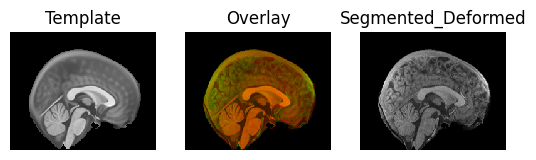

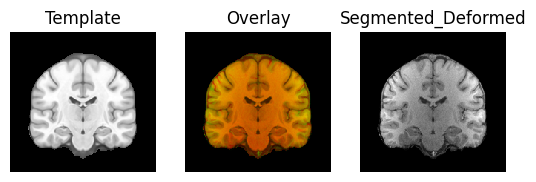

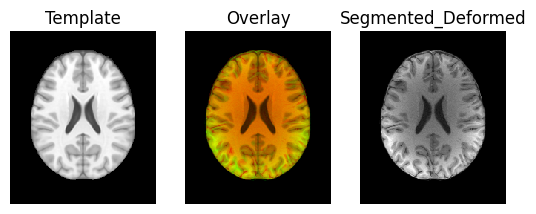

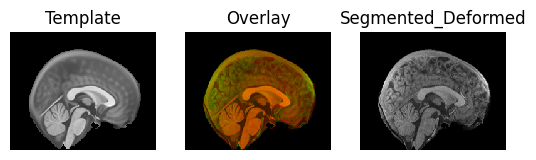

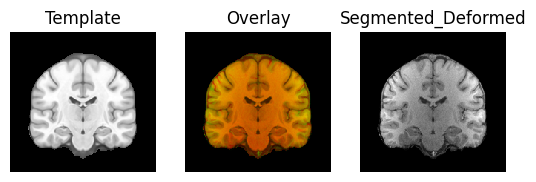

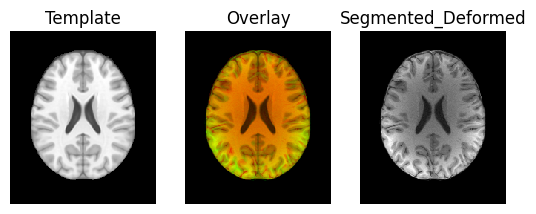

In [3]:
# Deformable registration setup
metric = CCMetric(3)  # Cross-Correlation Metric
level_iters = [10, 10, 5]  # Multi-resolution iterations
sdr = SymmetricDiffeomorphicRegistration(metric, level_iters)

# Perform deformable registration
mapping = sdr.optimize(template_data, moving_data, template_affine,
                       moving_affine, affine.affine)

# Apply the deformation field
warped_moving = mapping.transform(moving_data)

# Visualize deformable result
regtools.overlay_slices(template_data, warped_moving, None, 0, "Template", "Segmented_Deformed")
plt.show()
regtools.overlay_slices(template_data, warped_moving, None, 1, "Template", "Segmented_Deformed")
plt.show()
regtools.overlay_slices(template_data, warped_moving, None, 2, "Template", "Segmented_Deformed")
plt.show()

# Save the deformed volume with an absolute file path
output_dir = "segmented_deformable_registration"
os.makedirs(output_dir, exist_ok=True)
deformed_file = os.path.join(output_dir, "segmented_deformed_patient.nii")

deformed_img = nib.Nifti1Image(warped_moving, template_affine)
nib.save(deformed_img, deformed_file)

# Loop through slices and save as PNG
for axis in range(3):  # Iterate over axes (0: sagittal, 1: coronal, 2: axial)
    fig = regtools.overlay_slices(template_data, warped_moving, None, axis, 
                                  "Template", "Segmented_Deformed")
    plt.savefig(f"{output_dir}/segmented_deformed_registsegmented_deformed_patient_{axis}.png")


In [4]:
# %% Performance Metrics for Quantitative Comparison
from sklearn.metrics import mean_squared_error
from scipy.spatial.distance import dice

# Reload registered images to ensure proper variable definitions
affine_registered_img = nib.load("segmented_affine_registration/segmented_affine_patient.nii")
affine_registered_data = affine_registered_img.get_fdata()

deformed_registered_img = nib.load("segmented_deformable_registration/segmented_deformed_patient.nii")
deformed_registered_data = deformed_registered_img.get_fdata()

# Flatten the data for metrics calculation
template_flat = template_data.ravel()
affine_flat = affine_registered_data.ravel()
deformable_flat = deformed_registered_data.ravel()

# Mean Squared Error (MSE)
mse_affine = mean_squared_error(template_flat, affine_flat)
mse_deformable = mean_squared_error(template_flat, deformable_flat)

# Dice Similarity Coefficient (requires binary masks)
template_binary = (template_flat > 0).astype(int)
affine_binary = (affine_flat > 0).astype(int)
deformable_binary = (deformable_flat > 0).astype(int)

dice_affine = 1 - dice(template_binary, affine_binary)
dice_deformable = 1 - dice(template_binary, deformable_binary)

# Print metrics
print("Performance Metrics:")
print(f"MSE (Affine): {mse_affine:.4f}")
print(f"MSE (Deformable): {mse_deformable:.4f}")
print(f"Dice Similarity (Affine): {dice_affine:.4f}")
print(f"Dice Similarity (Deformable): {dice_deformable:.4f}")


Performance Metrics:
MSE (Affine): 84557.4735
MSE (Deformable): 103722.9819
Dice Similarity (Affine): 0.9100
Dice Similarity (Deformable): 0.9841


Deformation field dimensions: (197, 233, 189, 3)
Deformation field magnitude has been saved as NIfTI.


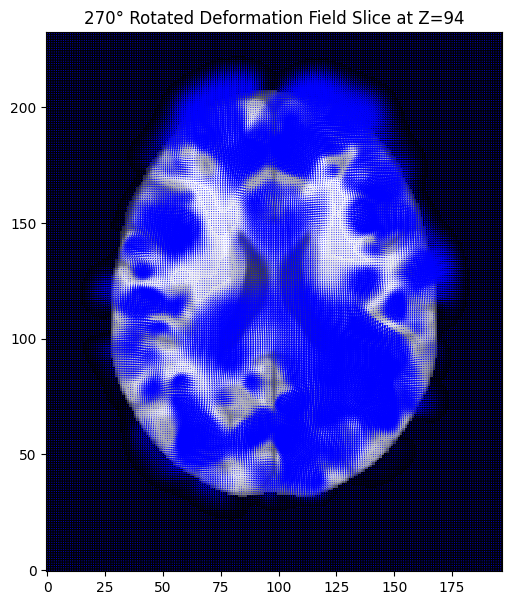

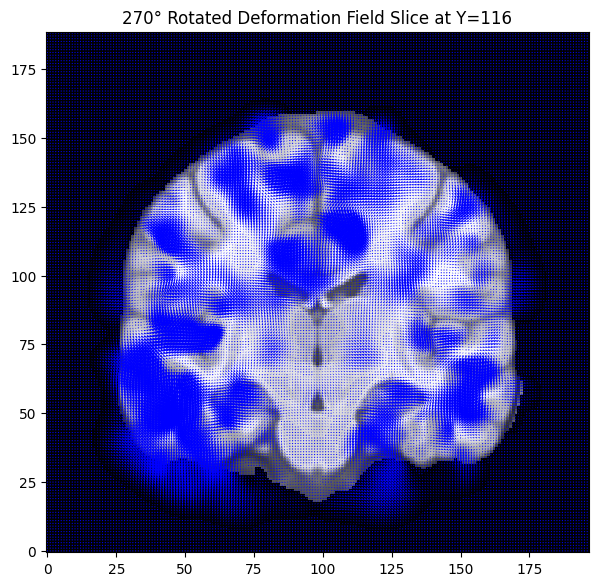

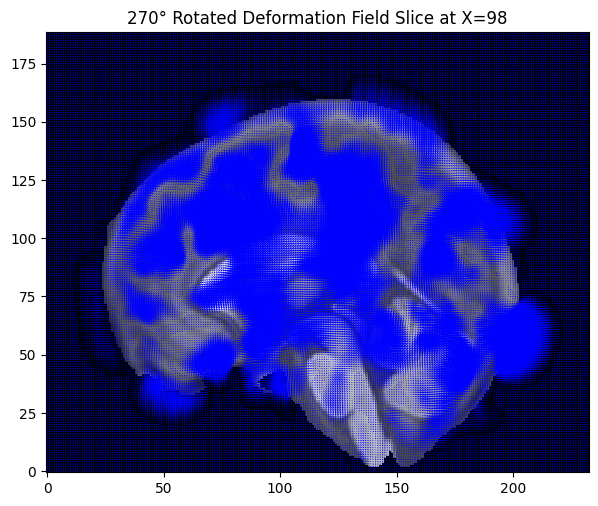

In [5]:
# %% Visualization of Deformation Field for Segmented Data
deformation_field = mapping.get_forward_field()
deformation_x = deformation_field[..., 0]
deformation_y = deformation_field[..., 1]
deformation_z = deformation_field[..., 2]

print("Deformation field dimensions:", deformation_field.shape)

# Calculate the deformation magnitude
deformation_magnitude = np.sqrt(np.sum(np.square(deformation_field), axis=-1))

# Save the deformation magnitude as NIfTI
# Store the scalar magnitude in the original atlas voxel order and geometry.
# This is a 3D magnitude map, not the 4D vector displacement field.
deformation_magnitude_img = nib.Nifti1Image(deformation_magnitude.astype(np.float32), template_affine)
nib.save(deformation_magnitude_img, "segmented_deformation_field_3D.nii")

print("Deformation field magnitude has been saved as NIfTI.")

# Visualization for the Z-plane
slice_idx_z = deformation_x.shape[2] // 2
slice_template_z = template_data[:, :, slice_idx_z]

fig, ax = plt.subplots(figsize=(7, 7))
rotated_slice_z = np.rot90(slice_template_z, k=3)
rotated_deformation_x_z = np.rot90(deformation_x[:, :, slice_idx_z], k=3)
rotated_deformation_y_z = np.rot90(deformation_y[:, :, slice_idx_z], k=3)
x_coords_z = np.arange(rotated_deformation_x_z.shape[1])
y_coords_z = np.arange(rotated_deformation_x_z.shape[0])
ax.imshow(rotated_slice_z, cmap='gray', origin='lower')
ax.quiver(x_coords_z, y_coords_z, rotated_deformation_x_z, rotated_deformation_y_z,
          color='blue', angles='xy', scale_units='xy', scale=1)
ax.set_title(f"270° Rotated Deformation Field Slice at Z={slice_idx_z}")
plt.savefig("segmented_deformationfield_axial.png")
plt.show()

# Visualization for the Y-plane
slice_idx_y = deformation_x.shape[1] // 2
slice_template_y = template_data[:, slice_idx_y, :]

fig, ax = plt.subplots(figsize=(7, 7))
rotated_slice_y = np.rot90(slice_template_y, k=3)
rotated_deformation_x_y = np.rot90(deformation_x[:, slice_idx_y, :], k=3)
rotated_deformation_z_y = np.rot90(deformation_z[:, slice_idx_y, :], k=3)
x_coords_y = np.arange(rotated_deformation_x_y.shape[1])
y_coords_y = np.arange(rotated_deformation_x_y.shape[0])
ax.imshow(rotated_slice_y, cmap='gray', origin='lower')
ax.quiver(x_coords_y, y_coords_y, rotated_deformation_x_y, rotated_deformation_z_y,
          color='blue', angles='xy', scale_units='xy', scale=1)
ax.set_title(f"270° Rotated Deformation Field Slice at Y={slice_idx_y}")
plt.savefig("segmented_deformationfield_coronal.png")
plt.show()

# Visualization for the X-plane
slice_idx_x = deformation_x.shape[0] // 2
slice_template_x = template_data[slice_idx_x, :, :]

fig, ax = plt.subplots(figsize=(7, 7))
rotated_slice_x = np.rot90(slice_template_x, k=3)
rotated_deformation_y_x = np.rot90(deformation_y[slice_idx_x, :, :], k=3)
rotated_deformation_z_x = np.rot90(deformation_z[slice_idx_x, :, :], k=3)
x_coords_x = np.arange(rotated_deformation_y_x.shape[1])
y_coords_x = np.arange(rotated_deformation_y_x.shape[0])
ax.imshow(rotated_slice_x, cmap='gray', origin='lower')
ax.quiver(x_coords_x, y_coords_x, rotated_deformation_y_x, rotated_deformation_z_x,
          color='blue', angles='xy', scale_units='xy', scale=1)
ax.set_title(f"270° Rotated Deformation Field Slice at X={slice_idx_x}")
plt.savefig("segmented_deformationfield_sagittal.png")
plt.show()
